  survey_id site_code        survey_start survey_end          survey_method  observation_hours  observed_bat_count  acoustic_detection_count  nightly_visit_count  colony_estimate  comparison_species_count observer_team survey_quality  weather_interference  survey_year  survey_month survey_season
BAT-0000001   KNT-KES 2019-01-05 18:00:00 2019-01-12 fixed_acoustic_station               28.6                 7.0                      13.0                  7.0              3.8                         8     TEAM-11-2           high                  32.0         2019             1        winter
BAT-0000002   KNT-KES 2019-02-05 18:00:00 2019-02-12    acoustic_and_visual               31.7                 8.0                      12.0                  9.0              7.3                        18     TEAM-11-2     acceptable                  18.5         2019             2        winter
BAT-0000003   KNT-KES 2019-03-05 18:00:00 2019-03-12 fixed_acoustic_station               32.4               

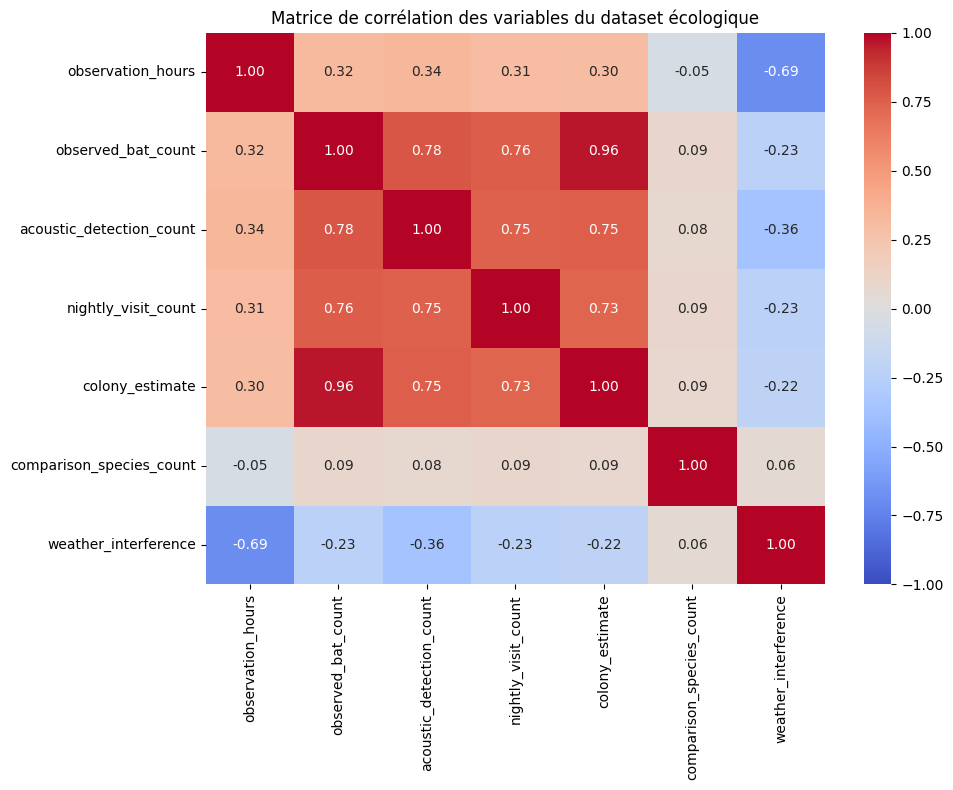

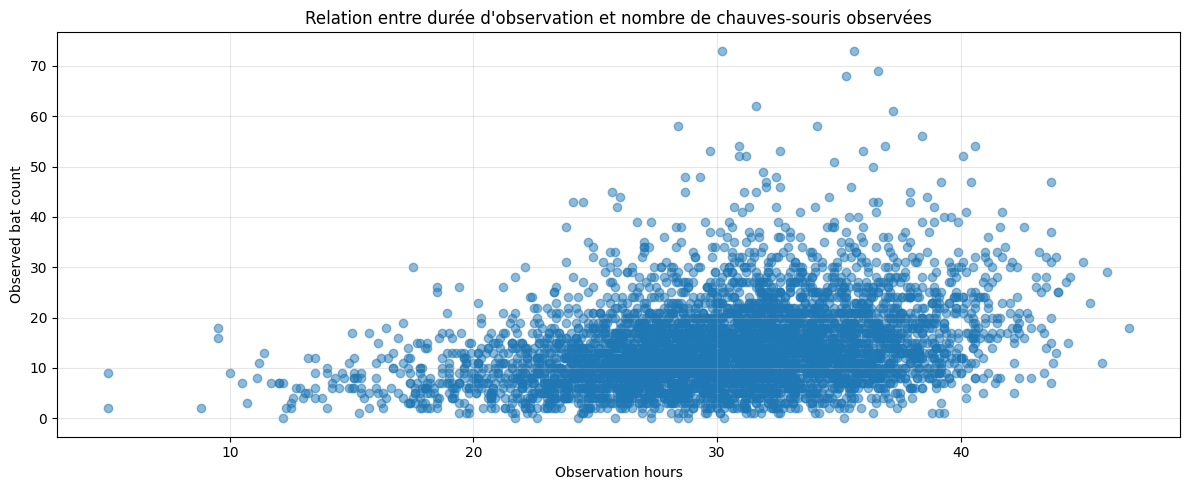

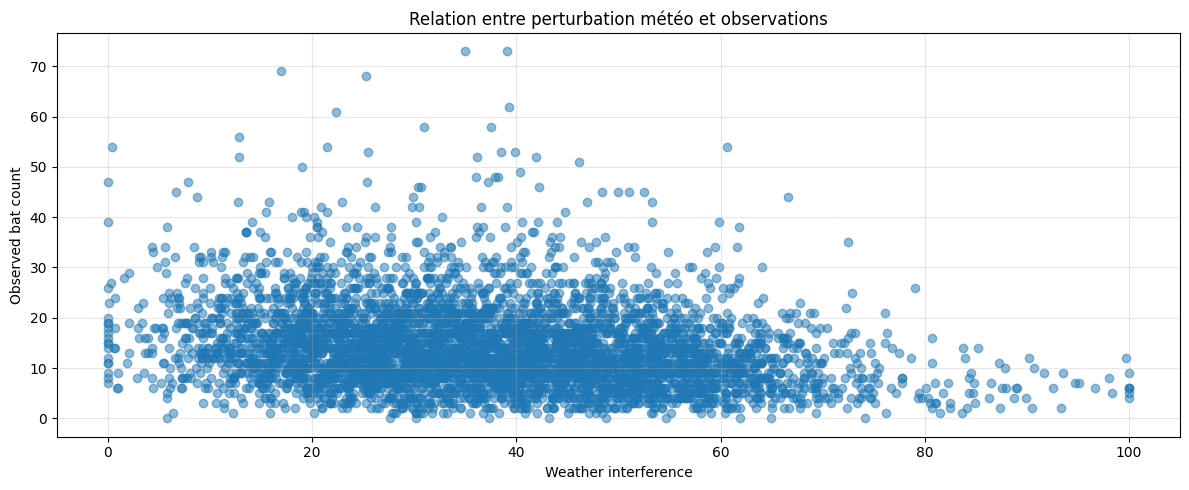

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def load_first_dataset():
    """Charge le premier dataset écologique depuis le dossier courant."""
    #file_path = Path(__file__).resolve().parent / "bat_surveys.csv"
    return pd.read_csv("data/ecology/bat_surveys.csv")


# Étape 1 : préparation de la base de données pour l'analyse
# On transforme les colonnes en types exploitables et on construit des variables utiles.

def prepare_dataset(df):
    """Nettoie et prépare le dataset pour l'analyse exploratoire."""
    df = df.copy()

    # 1) Conversion des dates en format datetime pour pouvoir exploiter année et saison #
    df["survey_start"] = pd.to_datetime(df["survey_start"], errors="coerce")
    df["survey_end"] = pd.to_datetime(df["survey_end"], errors="coerce")

    # 2) Conversion des colonnes numériques qui sont lues comme chaînes par pandas #
    numeric_cols = [
        "observation_hours",
        "observed_bat_count",
        "acoustic_detection_count",
        "nightly_visit_count",
    ]
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["colony_estimate"] = pd.to_numeric(df["colony_estimate"], errors="coerce")
    df["comparison_species_count"] = pd.to_numeric(
        df["comparison_species_count"], errors="coerce"
    )
    df["weather_interference"] = pd.to_numeric(
        df["weather_interference"], errors="coerce"
    )

    # 3) Remplissage des valeurs manquantes sur l'équipe d'observation #

    if "observer_team" in df.columns:
        mode_team = df["observer_team"].mode(dropna=True)
        if not mode_team.empty:
            df["observer_team"] = df["observer_team"].fillna(mode_team.iloc[0])
        else:
            df["observer_team"] = df["observer_team"].fillna("UNKNOWN")

    # 4) Création de variables temporelles utiles pour l'analyse #

    df["survey_year"] = df["survey_start"].dt.year
    df["survey_month"] = df["survey_start"].dt.month
    df["survey_season"] = df["survey_month"].apply(
        lambda m: "winter"
        if m in [12, 1, 2]
        else "spring"
        if m in [3, 4, 5]
        else "summer"
        if m in [6, 7, 8]
        else "autumn"
    )

    # 5) Conversion des variables catégorielles pour simplifier les analyses #

    df["survey_quality"] = df["survey_quality"].astype("category")
    df["survey_method"] = df["survey_method"].astype("category")
    df["site_code"] = df["site_code"].astype("category")

    return df


def explore_dataset(df):
    """Affiche une analyse exploratoire rapide du dataset."""
    print("\n=== ANALYSE EXPLORATOIRE ===")

    print("\n--- TOP 10 des sites les plus observés ---")
    print(df["site_code"].value_counts().head(10).to_string())

    print("\n--- Répartition des méthodes de relevé ---")
    print(df["survey_method"].value_counts().to_string())

    print("\n--- Répartition de la qualité des relevés ---")
    print(df["survey_quality"].value_counts().to_string())

    print("\n--- Moyenne de chauves-souris observées par année ---")
    print(df.groupby("survey_year")["observed_bat_count"].mean().round(2).to_string())

    print("\n--- Moyenne de chauves-souris observées par saison ---")
    print(df.groupby("survey_season")["observed_bat_count"].mean().round(2).to_string())

    corr_cols = [
        "observation_hours",
        "observed_bat_count",
        "acoustic_detection_count",
        "nightly_visit_count",
        "colony_estimate",
        "comparison_species_count",
        "weather_interference",
    ]
    corr = df[corr_cols].corr().round(3)
    print("\n--- Corrélations principales ---")
    print(corr.to_string())

    print("\n--- Statistiques descriptives ---")
    print(
        df[corr_cols]
        .describe()
        .round(2)
        .to_string()
    )

    # Visualisation de la corrélation entre variables numériques

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
    plt.title("Matrice de corrélation des variables du dataset écologique")
    plt.tight_layout()
    plt.show()

    # Comparaison visuelle entre le nombre observé et les autres variables

    plt.figure(figsize=(12, 5))
    plt.scatter(df["observation_hours"], df["observed_bat_count"], alpha=0.5)
    plt.xlabel("Observation hours")
    plt.ylabel("Observed bat count")
    plt.title("Relation entre durée d'observation et nombre de chauves-souris observées")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 5))
    plt.scatter(df["weather_interference"], df["observed_bat_count"], alpha=0.5)
    plt.xlabel("Weather interference")
    plt.ylabel("Observed bat count")
    plt.title("Relation entre perturbation météo et observations")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    
    # Charger le dataset brut


    df = load_first_dataset()

    # Préparer les données avant toute analyse

    df_clean = prepare_dataset(df)

    # Affichage de contrôle pour vérifier le bon nettoyage

    print(df_clean.head().to_string(index=False))
    print("\nDtypes:\n", df_clean.dtypes)
    print("\nValeurs manquantes:\n", df_clean.isna().sum())
    print(f"\nRows: {len(df_clean)}, Columns: {len(df_clean.columns)}")

    # Analyse exploratoire étape 2
    explore_dataset(df_clean)